# Flow Matching za linearnu regresiju (Hogg-ov problem)

**Zadatak od profesora:** rešiti jednostavan problem linearne regresije koristeći **Flow Matching**, da bismo videli da li ta tehnika može biti korisna za dalji rad.

**Šta radimo:** isti problem kao Vežba 1 iz Hogg-ovog rada — prava linija $y = m x + b$ kroz tačke 5–20 iz Tabele 1, sa poznatim greškama $\sigma_y$.
Za ovaj problem **znamo tačan posterior** (formula iz sekcije 1 Hogg-a), pa možemo precizno da proverimo da li Flow Matching radi.

**Potrebne biblioteke:** `numpy`, `matplotlib`, `torch` (PyTorch).
Ako nemaš PyTorch: `pip install torch` (ili `conda install pytorch -c pytorch`). Sve radi na običnom procesoru (CPU), bez grafičke karte.

| Deo | Šta radiš |
|---|---|
| 0 | Ideja Flow Matching-a, bez formula |
| 1 | Zagrevanje: Flow Matching na 2D "igrački" (da vidiš kako šum postaje podaci) |
| 2 | Linearna regresija: prior + generativni model (simulator) → trening skup |
| 3 | Uslovni Flow Matching: mreža uči posterior $p(m, b \mid \text{podaci})$ |
| 4 | Posterior za prave Hogg-ove podatke + poređenje sa tačnim rešenjem |
| 5 | "Amortizacija": nov skup podataka → posterior za delić sekunde; provera kalibracije |
| 6 | Rezime: Flow Matching vs. MCMC, ograničenja, pitanja za profesora |

## 0. Ideja Flow Matching-a (bez formula)

🔁 **Šta je problem?** Želimo da dobijemo **uzorke iz posteriora** $p(m, b \mid \text{podaci})$. Do sada smo to radili MCMC-om (ručni Metropolis–Hastings, emcee).

**Flow Matching radi drugačije:**
1. Krenemo od **"oblaka šuma"**: tačke iz obične Gausove raspodele $\mathcal{N}(0, I)$ — lako ih je generisati.
2. Neuronska mreža nauči **polje brzina** $v(\theta, t)$: za svaku tačku i svaki trenutak $t \in [0, 1]$ kaže *u kom pravcu i koliko brzo da se tačka pomeri*.
3. Kad pustimo tačke da "plutaju" po tom polju od $t = 0$ do $t = 1$, oblak šuma se **pretvori u oblik posteriora**.

**Metafora: reka.** Baciš 10.000 lišća na jedno mesto na reci (šum). Struja reke (polje brzina koje je mreža naučila) ih nosi i raspoređuje. Na kraju toka, lišće je raspoređeno tačno u obliku posteriora. Mreža "uči kako da teče reka".

**Kako mreža uči struju (trik Flow Matching-a):**
- Uzmemo jednu tačku šuma $\theta_0$ i jednu tačku iz ciljne raspodele $\theta_1$.
- Spojimo ih **pravom linijom**: $\theta_t = (1-t)\,\theta_0 + t\,\theta_1$. Brzina duž te linije je konstantna: $\theta_1 - \theta_0$.
- Mrežu treniramo da, za tačku $\theta_t$ u trenutku $t$, predvidi baš tu brzinu. To je obična regresija sa MSE loss-om!
- Kad se to ponovi milion puta sa nasumičnim parovima, mreža nauči "prosečnu struju" koja ceo oblak šuma prenosi u ciljni oblik.

**Zašto je ovo zanimljivo za inferencu (i za profesora):**
- Ne treba nam formula za verodostojnost — treba nam samo **simulator** (generativni model iz Hogg-a!) koji ume da pravi lažne podatke.
- Posle treninga, posterior za **bilo koji nov skup podataka** dobijamo za delić sekunde, bez ponovnog pokretanja MCMC-a ("amortizovana inferenca").
- Ovo se u literaturi zove *simulation-based inference*; konkretno ovaj pristup je **FMPE** (Flow Matching Posterior Estimation, Dax i sar. 2023).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import time

np.random.seed(0)
torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (7, 4.5)
print("PyTorch verzija:", torch.__version__)

PyTorch verzija: 2.15.0+cu132


## 1. Zagrevanje: Flow Matching na 2D igrački

🔁 **Cilj ovog dela:** da *vidiš* kako Flow Matching radi pre nego što ga primenimo na regresiju.
- **Ciljna raspodela:** dva odvojena "oblaka" tačaka (mešavina dve Gausove raspodele).
- **Start:** običan Gausov šum.
- Mreža uči polje brzina koje šum pretvara u dva oblaka.

Ovde nema uslova ("podataka") — mreža samo uči da generiše tačke iz jedne raspodele. U delu 3 dodajemo uslov.

In [2]:
def ciljni_uzorci(n):
    # Mešavina dva Gausa: centri na (-2, 0) i (2, 2)
    centri = np.array([[-2.0, 0.0], [2.0, 2.0]])
    k = np.random.randint(0, 2, n)
    return centri[k] + 0.4 * np.random.randn(n, 2)

class PoljeBrzina2D(nn.Module):
    # Mala mreža: ulaz (theta_t = 2 broja, t = 1 broj) -> izlaz brzina (2 broja)
    def __init__(self, h=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, h), nn.SiLU(),
                                 nn.Linear(h, h), nn.SiLU(),
                                 nn.Linear(h, 2))
    def forward(self, theta_t, t):
        return self.net(torch.cat([theta_t, t], dim=1))

v_toy = PoljeBrzina2D()
opt = torch.optim.Adam(v_toy.parameters(), lr=1e-3)

for it in range(3000):
    th1 = torch.tensor(ciljni_uzorci(256), dtype=torch.float32)   # tačke iz cilja
    th0 = torch.randn_like(th1)                                   # tačke šuma
    t = torch.rand(256, 1)                                        # nasumičan trenutak u [0, 1]
    th_t = (1 - t) * th0 + t * th1                                # tačka na pravoj liniji između njih
    cilj_brzina = th1 - th0                                       # brzina duž te linije
    loss = ((v_toy(th_t, t) - cilj_brzina) ** 2).mean()           # MSE: predviđena vs. prava brzina
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 1000 == 0:
        print(f"korak {it:4d}: loss = {loss.item():.3f}")

korak    0: loss = 3.808


korak 1000: loss = 1.776


korak 2000: loss = 2.096


### Plutanje po naučenom polju (Ojlerova metoda)

🔁 Da bismo pomerili tačke, rešavamo jednačinu $\dfrac{d\theta}{dt} = v(\theta, t)$ u malim koracima:
$$\theta_{t + \Delta t} = \theta_t + \Delta t \cdot v(\theta_t, t)$$
To je **Ojlerova metoda**: "pogledaj u kom pravcu struja nosi, napravi mali korak, ponovi". Sa $K = 100$ koraka, $\Delta t = 0{,}01$.

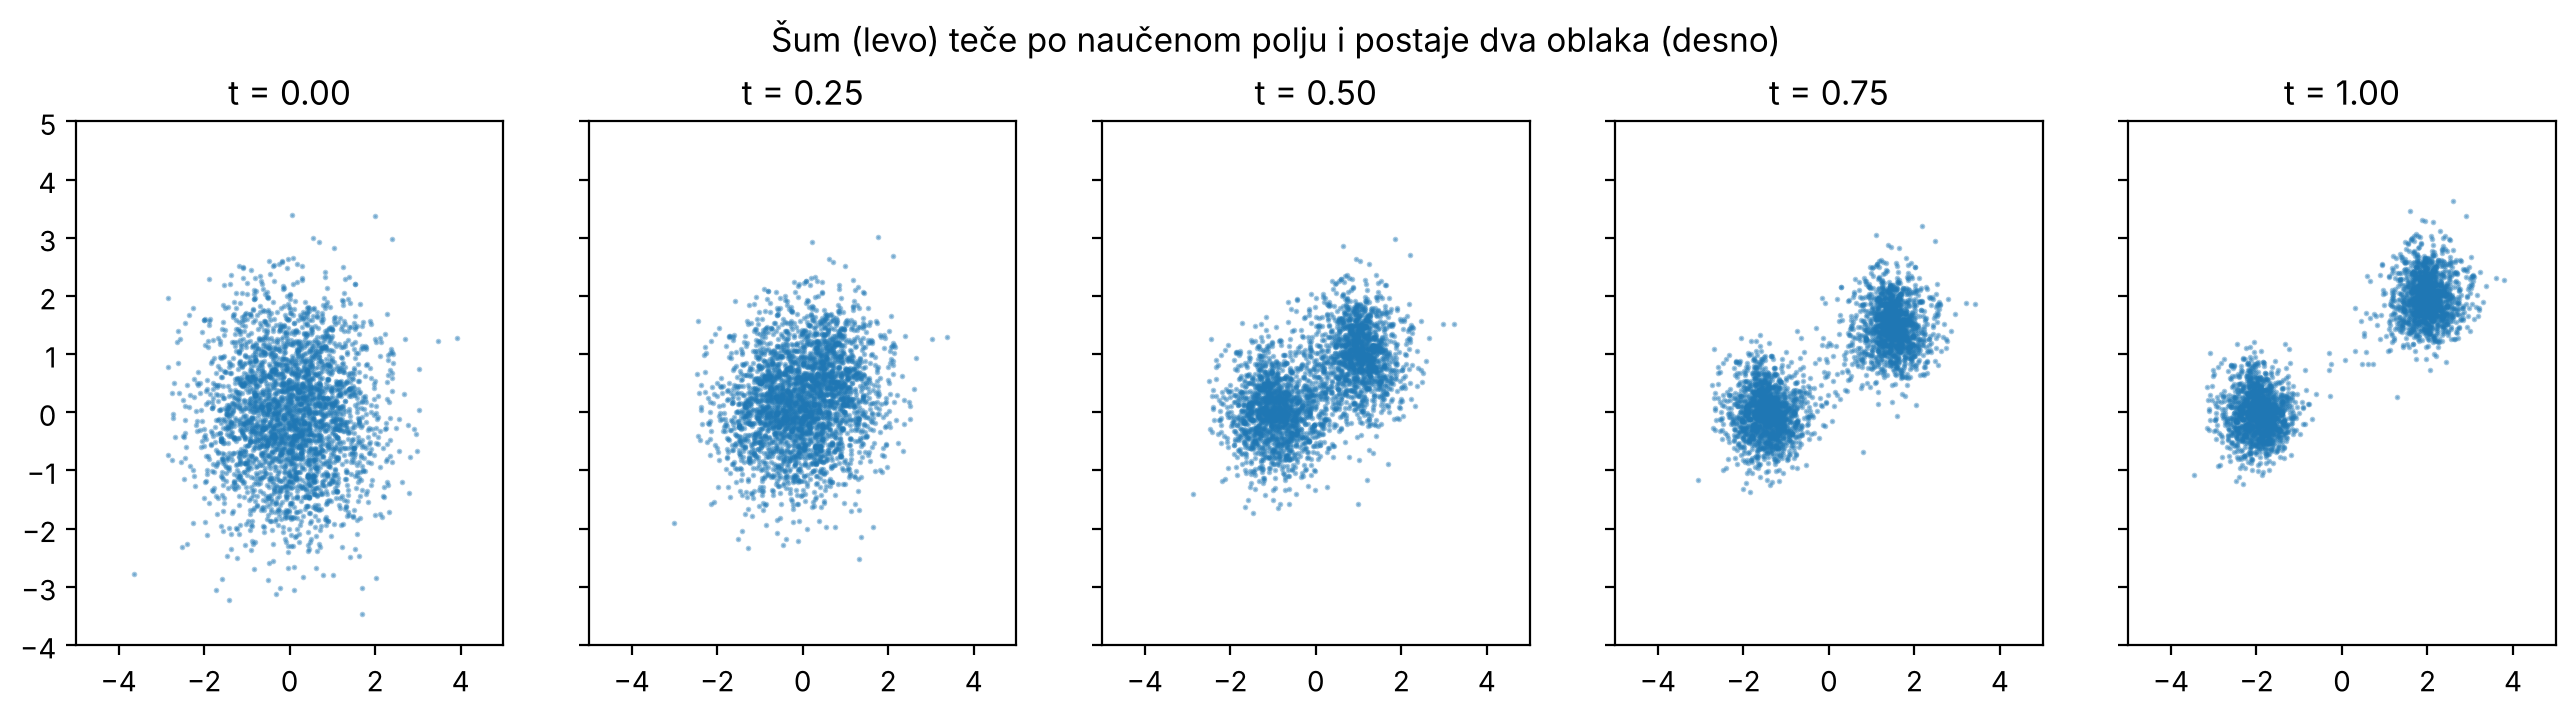

In [3]:
@torch.no_grad()
def pluti(v, n=3000, K=100, sacuvaj_u=(0, 25, 50, 75, 100)):
    z = torch.randn(n, 2)                 # start: šum
    snimci = {0: z.numpy().copy()}
    for k in range(K):
        t = torch.full((n, 1), k / K)
        z = z + v(z, t) / K               # Ojlerov korak
        if (k + 1) in sacuvaj_u:
            snimci[k + 1] = z.numpy().copy()
    return snimci

snimci = pluti(v_toy)
fig, axs = plt.subplots(1, 5, figsize=(16, 3.4), sharex=True, sharey=True)
for ax, (k, z) in zip(axs, snimci.items()):
    ax.scatter(z[:, 0], z[:, 1], s=1, alpha=0.4)
    ax.set_title(f"t = {k/100:.2f}")
    ax.set_xlim(-5, 5); ax.set_ylim(-4, 5)
plt.suptitle("Šum (levo) teče po naučenom polju i postaje dva oblaka (desno)", y=1.03)
plt.show()

**Šta vidiš:** na $t = 0$ je okrugao oblak šuma. Kako $t$ raste, tačke se razdvajaju i na $t = 1$ formiraju dva oblaka — tačno ciljnu raspodelu. Mreža nikad nije "videla formulu" ciljne raspodele, samo uzorke iz nje.

## 2. Linearna regresija: prior, simulator i trening skup

🔁 **Podsetnik (Hogg, sekcija 1–2)**
- Model: $y_i = m\,x_i + b + \varepsilon_i$, gde je $\varepsilon_i \sim \mathcal{N}(0, \sigma_{yi}^2)$.
- Ovo **je generativni model** — recept za pravljenje podataka. Flow Matching-u treba baš to: simulator.
- Koristimo tačke 5–20 (bez autlajera) i poznate $\sigma_y$.

**Prior:** ravan (uniform) u "kutiji" $m \in [1;\ 3{,}5]$, $b \in [-150;\ 250]$ — široko, tako da tačan odgovor ($m \approx 2{,}24$, $b \approx 34$) bude daleko od ivica.

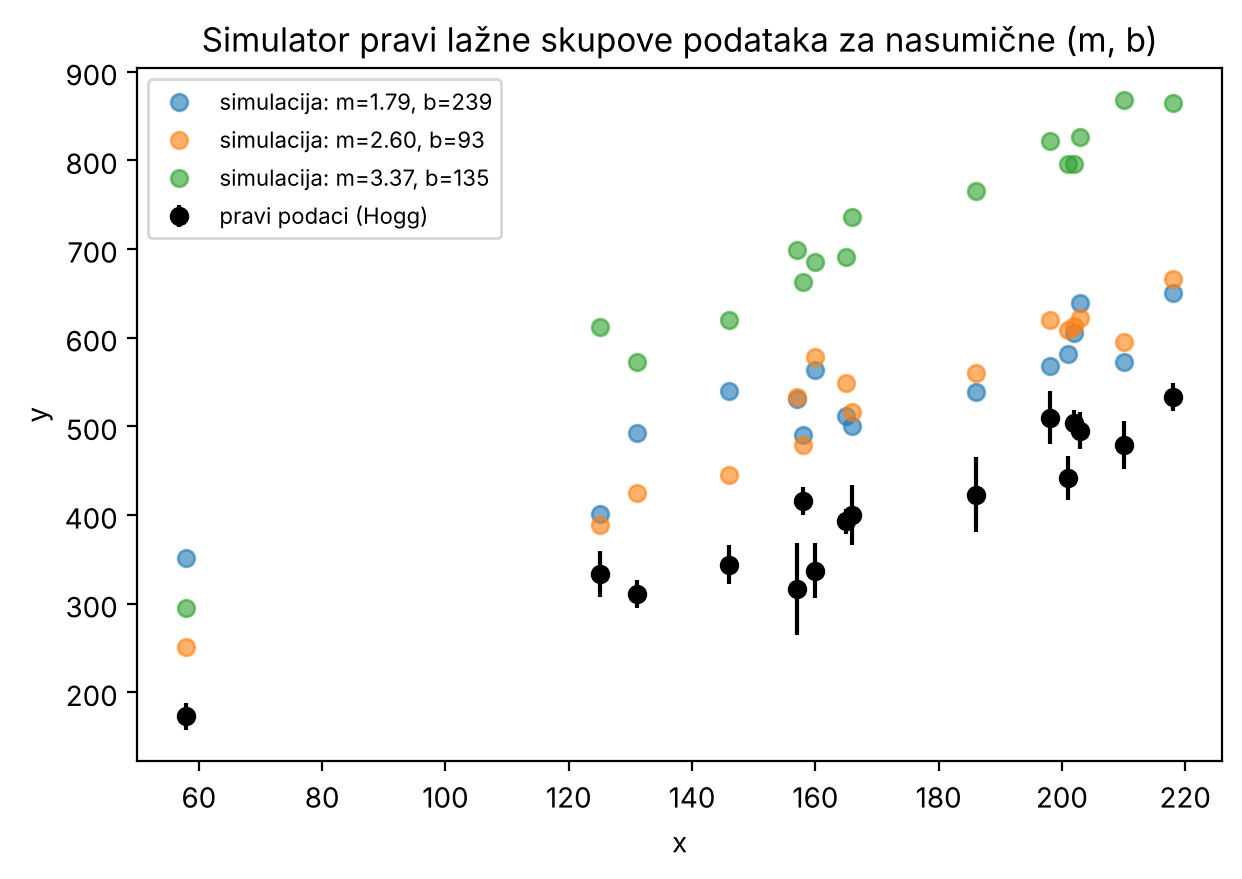

In [4]:
# Hogg Tabela 1, tačke 5–20: x, y, sigma_y
T1 = np.array([[203,495,21],[58,173,15],[210,479,27],[202,504,14],[198,510,30],[158,416,16],
               [165,393,14],[201,442,25],[157,317,52],[131,311,16],[166,400,34],[160,337,31],
               [186,423,42],[125,334,26],[218,533,16],[146,344,22]], float)
x, y_obs, sy = T1.T
n_tacaka = len(x)

# Prior: ravan u kutiji
prior_dole = np.array([1.0, -150.0])   # [m_min, b_min]
prior_gore = np.array([3.5,  250.0])   # [m_max, b_max]

def uzorak_iz_priora(n):
    return prior_dole + (prior_gore - prior_dole) * np.random.rand(n, 2)   # kolone: [m, b]

def simulator(theta):
    # Generativni model: za svaki par (m, b) napravi 16 lažnih y vrednosti
    m, b = theta[:, [0]], theta[:, [1]]
    return m * x + b + sy * np.random.randn(len(theta), n_tacaka)

# Primer: tri nasumična para (m, b) i njihovi lažni podaci
primer = uzorak_iz_priora(3)
lazni = simulator(primer)
plt.errorbar(x, y_obs, yerr=sy, fmt="ok", label="pravi podaci (Hogg)")
for i in range(3):
    plt.plot(x, lazni[i], "o", alpha=0.6, label=f"simulacija: m={primer[i,0]:.2f}, b={primer[i,1]:.0f}")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(fontsize=8)
plt.title("Simulator pravi lažne skupove podataka za nasumične (m, b)"); plt.show()

### Trening skup: 200.000 parova (parametri, lažni podaci)

🔁 Svaki red trening skupa je jedan par: "**ovi parametri** su napravili **ove podatke**". Mreža iz miliona takvih primera uči obrnut smer: "za **ove podatke**, koji su **parametri** verovatni?" — to je posterior.

**Normalizacija:** $m$ je oko 2, a $b$ oko 50 — vrlo različite skale. Mreže bolje uče kad su svi brojevi oko 0 sa rasipanjem oko 1, pa oduzmemo prosek i podelimo standardnom devijacijom (i za parametre i za podatke). Na kraju vratimo nazad.

In [5]:
N = 200_000
theta_trening = uzorak_iz_priora(N)       # (N, 2)
y_trening = simulator(theta_trening)       # (N, 16)

# Normalizacija (pamtimo prosek i std da bismo kasnije vratili u prave jedinice)
th_mean, th_std = theta_trening.mean(0), theta_trening.std(0)
y_mean,  y_std  = y_trening.mean(0),     y_trening.std(0)

TH = torch.tensor((theta_trening - th_mean) / th_std, dtype=torch.float32)
Y  = torch.tensor((y_trening    - y_mean)  / y_std,  dtype=torch.float32)
print("Oblik parametara:", TH.shape, "  oblik podataka:", Y.shape)

Oblik parametara: torch.Size([200000, 2])   oblik podataka: torch.Size([200000, 16])


## 3. Uslovni Flow Matching: mreža uči posterior

🔁 **Razlika u odnosu na igračku iz dela 1:** sada mreža dobija i **podatke** $y$ kao ulaz:
$$v(\theta_t,\ t,\ y) \quad\text{— ulaz: 2 + 1 + 16 = 19 brojeva, izlaz: 2 broja}$$
Za različite podatke, struja reke je različita, pa se šum pretvara u **različit posterior**.

**Loss (isti trik kao u delu 1):**
$$\mathcal{L} = \mathbb{E}\left[\,\left\| v\big((1-t)\theta_0 + t\theta_1,\ t,\ y\big) - (\theta_1 - \theta_0) \right\|^2\,\right]$$
- $\theta_1, y$ = jedan red trening skupa (pravi parametri i njihovi lažni podaci)
- $\theta_0$ = šum, $t$ = nasumičan trenutak

In [6]:
class UslovnoPolje(nn.Module):
    def __init__(self, dim_theta=2, dim_y=16, h=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim_theta + 1 + dim_y, h), nn.SiLU(),
            nn.Linear(h, h), nn.SiLU(),
            nn.Linear(h, h), nn.SiLU(),
            nn.Linear(h, dim_theta))
    def forward(self, theta_t, t, y):
        return self.net(torch.cat([theta_t, t, y], dim=1))

torch.manual_seed(0)
v = UslovnoPolje()
broj_koraka = 15_000
opt = torch.optim.Adam(v.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, broj_koraka)   # stopa učenja polako opada
istorija = []

t_start = time.time()
for it in range(broj_koraka):
    idx = torch.randint(0, N, (512,))           # mini-batch od 512 redova
    th1, y = TH[idx], Y[idx]                    # pravi parametri + njihovi lažni podaci
    th0 = torch.randn_like(th1)                 # šum
    t = torch.rand(512, 1)                      # trenutak
    th_t = (1 - t) * th0 + t * th1              # tačka na pravoj liniji
    loss = ((v(th_t, t, y) - (th1 - th0)) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    istorija.append(loss.item())
    if it % 3000 == 0:
        print(f"korak {it:5d}: loss = {loss.item():.3f}")
print(f"Trening trajao {time.time() - t_start:.0f} s")

korak     0: loss = 1.921


korak  3000: loss = 0.181


korak  6000: loss = 0.199


korak  9000: loss = 0.155


korak 12000: loss = 0.192


Trening trajao 29 s


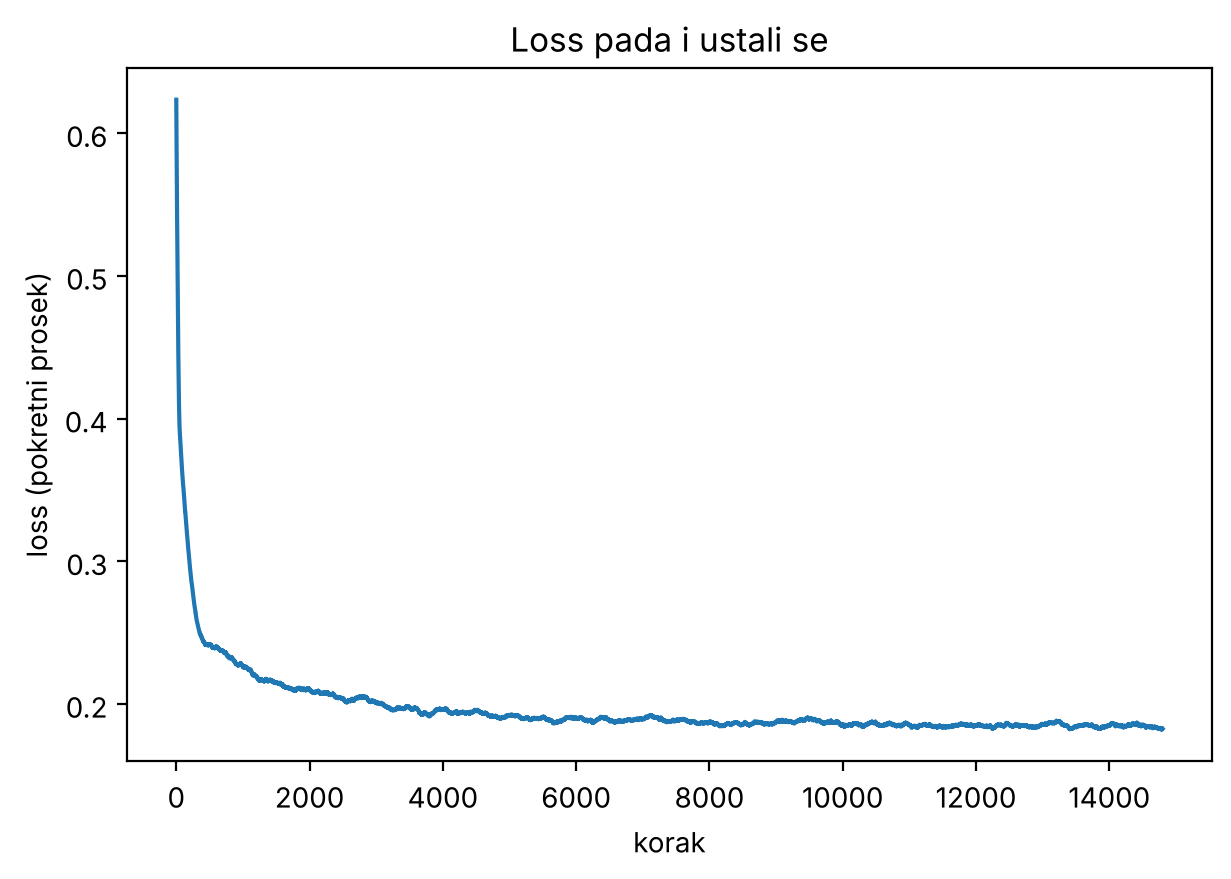

In [7]:
plt.plot(np.convolve(istorija, np.ones(200)/200, mode="valid"))
plt.xlabel("korak"); plt.ylabel("loss (pokretni prosek)")
plt.title("Loss pada i ustali se"); plt.show()

⚠️ **Zašto loss ne ide na nulu?** Za istu tačku $\theta_t$ postoji mnogo mogućih parova (šum, cilj) koji kroz nju prolaze, sa različitim brzinama. Mreža može da nauči samo njihov **prosek**, pa ostaje "neizbežan" ostatak. To je normalno — bitno je da se loss **ustali**, a pravi test je deo 4.

## 4. Posterior za prave Hogg-ove podatke

🔁 Uzmemo **prave** $y$ vrednosti, normalizujemo ih, pa pustimo 20.000 tačaka šuma da plutaju po polju $v(\theta, t, y_{\text{obs}})$. Rezultat su uzorci posteriora za $(m, b)$.

In [8]:
@torch.no_grad()
def posterior_uzorci(y_podaci, n=20_000, K=100):
    y = torch.tensor((y_podaci - y_mean) / y_std, dtype=torch.float32).repeat(n, 1)
    z = torch.randn(n, 2)                         # šum
    for k in range(K):
        t = torch.full((n, 1), k / K)
        z = z + v(z, t, y) / K                    # Ojlerov korak
    return z.numpy() * th_std + th_mean           # nazad u prave jedinice: kolone [m, b]

t0 = time.time()
uzorci = posterior_uzorci(y_obs)
print(f"20.000 uzoraka posteriora za {time.time()-t0:.2f} s")

20.000 uzoraka posteriora za 1.03 s


### Tačan posterior (za poređenje)

🔁 Za ravan prior i Gausove greške, posterior je Gausov, sa sredinom i kovarijansom iz formule najmanjih kvadrata (Hogg, sekcija 1):
$X = [A^\top C^{-1} A]^{-1} A^\top C^{-1} Y$, kovarijansa $= [A^\top C^{-1} A]^{-1}$.

In [9]:
A = np.vstack([np.ones_like(x), x]).T
Cinv = np.diag(1 / sy**2)
cov_tacno = np.linalg.inv(A.T @ Cinv @ A)          # redosled [b, m]
b_t, m_t = cov_tacno @ (A.T @ Cinv @ y_obs)
sig_b, sig_m = np.sqrt(np.diag(cov_tacno))
rho_t = cov_tacno[0, 1] / (sig_b * sig_m)

m_fm, b_fm = uzorci[:, 0], uzorci[:, 1]
print(f"{'':12}{'m':>18}{'b':>18}{'korelacija':>14}")
print(f"{'tačno':12}{f'{m_t:.3f} ± {sig_m:.3f}':>18}{f'{b_t:.1f} ± {sig_b:.1f}':>18}{rho_t:>14.3f}")
print(f"{'Flow Match.':12}{f'{m_fm.mean():.3f} ± {m_fm.std():.3f}':>18}{f'{b_fm.mean():.1f} ± {b_fm.std():.1f}':>18}{np.corrcoef(m_fm, b_fm)[0,1]:>14.3f}")

                             m                 b    korelacija
tačno            2.240 ± 0.108       34.0 ± 18.2        -0.961
Flow Match.      2.250 ± 0.113       32.8 ± 18.9        -0.977


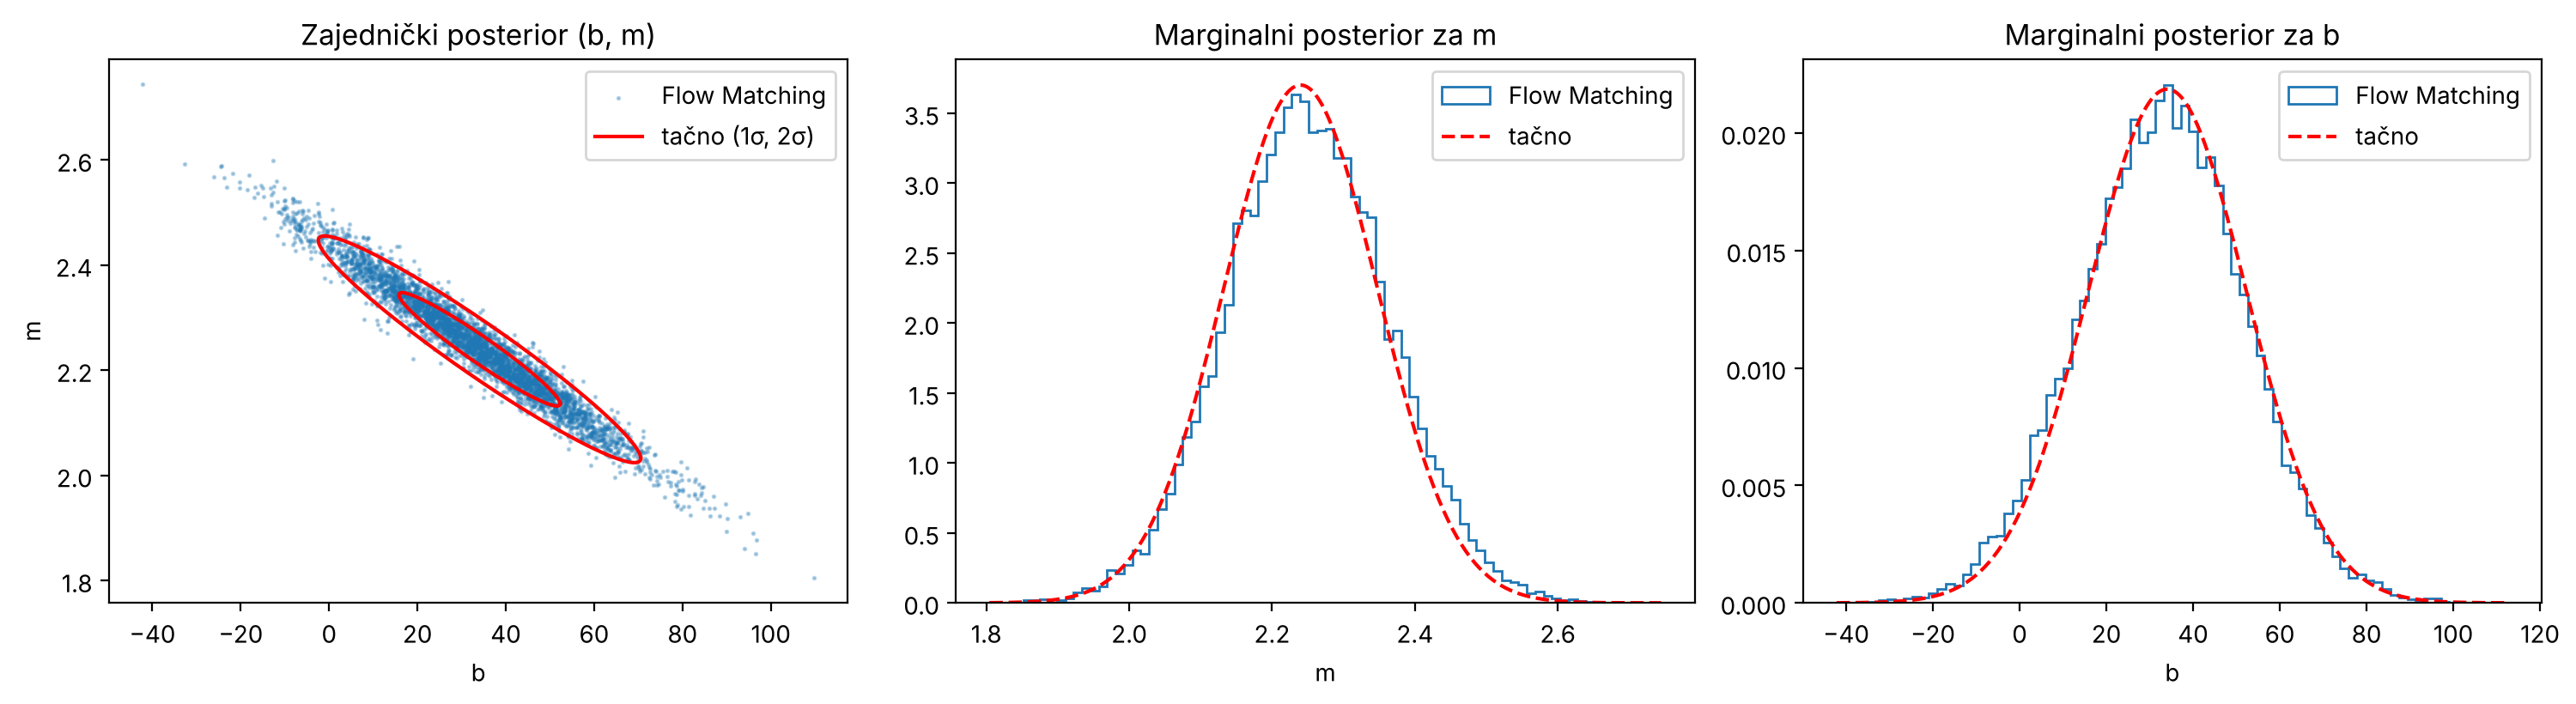

In [10]:
# Tačni Gausov posterior: uzorci za crtanje kontura
tacni = np.random.multivariate_normal([b_t, m_t], cov_tacno, size=20000)[:, ::-1]   # -> kolone [m, b]

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
axs[0].scatter(b_fm[::5], m_fm[::5], s=1, alpha=0.3, label="Flow Matching")
# elipse 1σ i 2σ tačnog posteriora
ugao = np.linspace(0, 2*np.pi, 200)
L = np.linalg.cholesky(cov_tacno)
for k in [1, 2]:
    e = (L @ np.vstack([np.cos(ugao), np.sin(ugao)])) * k
    axs[0].plot(b_t + e[0], m_t + e[1], "r", lw=1.5, label="tačno (1σ, 2σ)" if k == 1 else None)
axs[0].set_xlabel("b"); axs[0].set_ylabel("m"); axs[0].legend(); axs[0].set_title("Zajednički posterior (b, m)")

axs[1].hist(m_fm, 80, density=True, histtype="step", color="C0", label="Flow Matching")
tt = np.linspace(m_fm.min(), m_fm.max(), 300)
axs[1].plot(tt, np.exp(-(tt-m_t)**2/(2*sig_m**2))/np.sqrt(2*np.pi*sig_m**2), "r--", label="tačno")
axs[1].set_xlabel("m"); axs[1].legend(); axs[1].set_title("Marginalni posterior za m")

axs[2].hist(b_fm, 80, density=True, histtype="step", color="C0", label="Flow Matching")
tt = np.linspace(b_fm.min(), b_fm.max(), 300)
axs[2].plot(tt, np.exp(-(tt-b_t)**2/(2*sig_b**2))/np.sqrt(2*np.pi*sig_b**2), "r--", label="tačno")
axs[2].set_xlabel("b"); axs[2].legend(); axs[2].set_title("Marginalni posterior za b")
plt.tight_layout(); plt.show()

**Kako da čitaš grafike:**
- **Levo:** plave tačke su uzorci iz Flow Matching-a, crvene elipse su tačan posterior (unutrašnja sadrži ~39%, spoljašnja ~86% verovatnoće u 2D). Ako se plavi oblak poklapa sa elipsama — Flow Matching je naučio tačan posterior, **uključujući korelaciju** (kosa elipsa: veći m ↔ manji b, isto kao u Hogg notebook-u).
- **Sredina i desno:** histogrami uzoraka (plavo) vs. tačna Gausova kriva (crveno). Poklapanje znači da su i najbolja vrednost i nesigurnost tačni.

Male razlike su normalne: mreža je naučena na konačnom broju primera i konačno dugo. Više primera, duži trening ili veća mreža ih smanjuju.

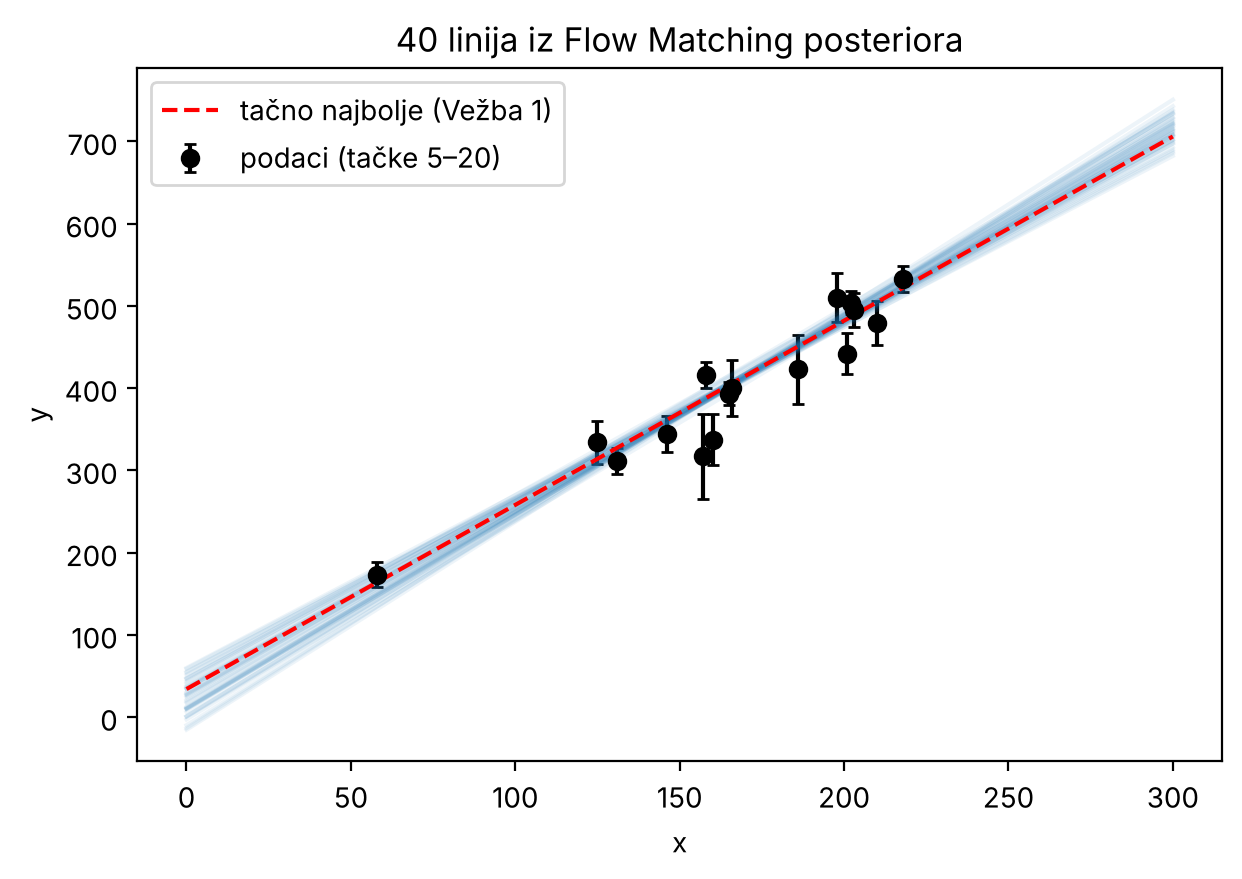

In [11]:
# Linije iz posteriora preko podataka
xx = np.linspace(0, 300, 100)
plt.errorbar(x, y_obs, yerr=sy, fmt="ok", capsize=2, label="podaci (tačke 5–20)")
for k in np.random.randint(0, len(uzorci), 40):
    plt.plot(xx, uzorci[k, 0]*xx + uzorci[k, 1], color="C0", alpha=0.08)
plt.plot(xx, m_t*xx + b_t, "r--", label="tačno najbolje (Vežba 1)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.title("40 linija iz Flow Matching posteriora"); plt.show()

## 5. Amortizacija i provera kalibracije

🔁 **Amortizacija:** mreža je istrenirana **jednom**. Sada za **bilo koji nov skup podataka** (isti x i σ, druge y vrednosti) posterior dobijamo odmah — bez novog treninga i bez MCMC-a.

**Metafora:** MCMC je kao da za svaki novi grad crtaš mapu od nule, pešice. Flow Matching je kao da si jednom napravila GPS koji radi za sve gradove — skupo je napraviti, ali posle je svaki upit trenutan.

**Provera kalibracije (da li su nesigurnosti poštene):**
1. Izvučemo 300 "pravih" $(m, b)$ iz priora i simuliramo podatke.
2. Za svaki skup dobijemo posterior iz Flow Matching-a.
3. Brojimo koliko puta je prava vrednost unutar centralnog 68% intervala posteriora. **Ako su nesigurnosti poštene, to treba da bude ≈ 68%** (i ≈ 95% za 95% interval).

In [12]:
np.random.seed(1)
n_test = 300
theta_test = uzorak_iz_priora(n_test)
y_test = simulator(theta_test)

pogodak68 = np.zeros((n_test, 2)); pogodak95 = np.zeros((n_test, 2))
t0 = time.time()
for i in range(n_test):
    s = posterior_uzorci(y_test[i], n=2000)
    for j in range(2):
        lo68, hi68 = np.percentile(s[:, j], [16, 84])
        lo95, hi95 = np.percentile(s[:, j], [2.5, 97.5])
        pogodak68[i, j] = lo68 <= theta_test[i, j] <= hi68
        pogodak95[i, j] = lo95 <= theta_test[i, j] <= hi95
print(f"{n_test} posteriora za {time.time()-t0:.1f} s  (~{(time.time()-t0)/n_test*1000:.0f} ms po skupu podataka)")
print(f"\n{'':6}{'u 68% intervalu':>18}{'u 95% intervalu':>18}")
for j, ime in enumerate(["m", "b"]):
    print(f"{ime:6}{pogodak68[:, j].mean():>17.0%} {pogodak95[:, j].mean():>17.0%}")
print("\nOčekivano: ~68% i ~95% (uz statističko odstupanje od nekoliko % zbog samo 300 testova)")

300 posteriora za 31.0 s  (~103 ms po skupu podataka)

         u 68% intervalu   u 95% intervalu
m                   66%               96%
b                   66%               95%

Očekivano: ~68% i ~95% (uz statističko odstupanje od nekoliko % zbog samo 300 testova)


⚠️ **Napomena o ivicama priora:** ako je prava vrednost blizu ivice kutije priora, pravi posterior je "odsečen" na ivici. Flow Matching to mora da nauči iz primera, pa je tamo najmanje precizan. Zato je prior biran široko u odnosu na stvarne podatke.

## 6. Rezime

| | MCMC (Metropolis–Hastings, emcee) | Flow Matching (FMPE) |
|---|---|---|
| Šta mu treba | formula za **verodostojnost** (`log_prob`) | samo **simulator** (generativni model) |
| Trošak | svaki novi skup podataka = novo pokretanje lanca | skup trening jednom, posle svaki skup za ~ms |
| Tačnost | asimptotski tačan (dug lanac) | onoliko tačan koliko je mreža dobro naučena |
| Provera | trace plot, τ, stopa prihvatanja | loss, provera kalibracije na simulacijama (deo 5) |
| Kada je bolji | malo podataka, verodostojnost lako izračunati | mnogo skupova podataka, ili je verodostojnost nepoznata/preskupa, ali simulacija moguća |

**Glavne pouke:**
1. Flow Matching uči **polje brzina** koje šum pretvara u posterior; trening je obična MSE regresija na brzinu $\theta_1 - \theta_0$ duž prave linije.
2. Za inferencu mu treba **samo generativni model** — tačno ono što Hogg kaže da uvek treba napisati.
3. Na problemu linearne regresije, gde znamo tačan odgovor, Flow Matching je naučio i sredinu, i nesigurnost, i korelaciju (m, b).
4. Kalibracija na simulacijama pokazuje da su nesigurnosti poštene.

**Moguća proširenja (za probu ili za razgovor sa profesorom):**
- **Autlajeri:** simulator koji sa verovatnoćom $P_b$ pravi lošu tačku (Hogg-ov mešavinski model), pa učiti posterior na svih 20 tačaka — bez pisanja komplikovane verodostojnosti.
- **Nepoznata σ:** dodati σ (ili faktor f kao u emcee tutorijalu) kao treći parametar.
- **Fizički model umesto linije:** npr. prigušeni harmonijski oscilator — simulator rešava jednačinu, Flow Matching uči posterior za $\mu$. Veza sa PINN zadatkom!

**Pitanja za profesora:**
1. Da li je ideja da Flow Matching koristimo za **amortizovanu inferencu** (mnogo objekata, npr. mnogo galaksija/zvezda sa istim modelom)?
2. Da li bi simulator u našem problemu bio numeričko rešenje jednačine, ili bi PINN mogao da bude brz **surogat-simulator**?
3. Kako da biramo prior i broj simulacija za trening u realnom problemu?

**Literatura:**
- Lipman i sar. (2023), *Flow Matching for Generative Modeling*, arXiv:2210.02747
- Dax i sar. (2023), *Flow Matching for Scalable Simulation-Based Inference*, arXiv:2305.17161